# 07. Модель для текущего рынка: обучение на 2024–2026, проверка на самых новых вакансиях

Модели 01–06 обучены на вакансиях февраля–марта 2024. Анализ динамики (репозиторий kg-job-market-analysis,
ноутбук 08) показал, что та же вакансия с тех пор подорожала примерно на 31%. Значит, модель 2024 года
для сегодняшних вакансий будет **занижать** зарплату.

**Данные:** `vacancies_2024_2026.csv` (hh, lalafo, Telegram-каналы codifynews и kgworkzone, январь 2024 – октябрь 2026).

**Честная проверка во времени:** модель учится только на прошлом и проверяется на будущем.

| Часть | Период | Зачем |
|---|---|---|
| обучение | январь 2024 – июнь 2026 | подбор весов |
| калибровка | апрель–июнь 2026 (последний квартал обучения) | ширина диапазонов |
| **тест** | **июль – октябрь 2026** | ошибка на вакансиях, которых модель не видела, из «будущего» |

Повторные публикации одной вакансии (тот же заголовок и начало текста) из теста удаляются, если они уже
были в обучении: иначе модель «узнавала» бы ответ.

**Сравниваются:**
- **A.** финальная модель 2024 года (`final_model.joblib`) как есть, без переобучения;
- **B.** та же модель, переобученная на всех данных 2024–2026, без признака времени;
- **C.** B + признак времени (номер месяца публикации);
- **D.** C + работодатель (`company`);
- **E.** D, но только на вакансиях с 2025 года;
- базовые уровни: медиана рынка и медиана профессии за последние 6 месяцев обучения.

In [1]:
import sys, json, time
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
import prep

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

df = prep.load("../data/vacancies_2024_2026.csv")
df["published"] = pd.to_datetime(df["published"])
df = df[df["published"] >= "2024-01-01"].copy()
df["company"] = df["company"].fillna("не указано").astype(str).str.lower().str.strip()
df["experience_known"] = df["experience_known"].fillna(True).astype(int)
# месяц публикации: 0 = январь 2024
df["month_n"] = (df["published"].dt.year - 2024) * 12 + df["published"].dt.month - 1

# шумные метки: как в prep.labeled, но фильтр 5x применяется ко всем источникам со свободным текстом
d = df[df["has_salary"]].copy()
ratio = d["salary_kgs"] / d.groupby("sub_category")["salary_kgs"].transform("median")
noise = ((ratio > 5) | (ratio < 0.2)) & d["source"].isin(["lalafo", "telegram_kgworkzone"])
d = d[~noise].copy()
d["y"] = np.log(d["salary_kgs"])
print(f"Вакансий с зарплатой: {len(d)} (убрано как шум: {noise.sum()})")

TEST_FROM, CAL_FROM = pd.Timestamp("2026-07-01"), pd.Timestamp("2026-04-01")
train = d[d["published"] < TEST_FROM].reset_index(drop=True)
test = d[d["published"] >= TEST_FROM]
n0 = len(test)
test = test[~test["dup_group"].isin(set(train["dup_group"]))].reset_index(drop=True)
print(f"Обучение: {len(train)} | тест: {len(test)} (убрано повторов из обучения: {n0 - len(test)})")
pd.crosstab(test["source"], test["published"].dt.to_period("M"))

/home/claude/kg-salary-prediction/notebooks/../src/prep.py:41: DtypeWarning: Columns (0: skills, 1: requirements, 2: responsibilities) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Вакансий с зарплатой: 22681 (убрано как шум: 29)
Обучение: 20499 | тест: 1076 (убрано повторов из обучения: 1106)


published,2026-07,2026-08,2026-09,2026-10
source,,,,
telegram_codifynews,188,161,180,167
telegram_kgworkzone,141,82,108,49


## Модели

In [2]:
P = json.load(open("../models/final_model_meta.json"))["params"]
C, N, B = prep.CAT_FEATURES, prep.NUM_FEATURES, prep.BOOL_FEATURES + ["experience_known"]

def build(cat, num, p=P):
    ct = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=p["min_freq"]), cat),
        ("num", StandardScaler(), num),
        ("t", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, ngram_range=(1, p["word_ngram"]),
                              max_features=p["word_max"]), "full"),
        ("ti", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, analyzer="char_wb",
                               ngram_range=(2, p["char_max"])), "title"),
    ], transformer_weights={"ti": p["title_weight"]})
    return make_pipeline(ct, Ridge(alpha=p["alpha"]))

VARIANTS = {
    "B. 2024–2026, без времени":        (C, N + B, None),
    "C. + месяц публикации":            (C, N + B + ["month_n"], None),
    "D. + работодатель":                (C + ["company"], N + B + ["month_n"], None),
    "E. как D, только 2025–2026":       (C + ["company"], N + B + ["month_n"], "2025-01-01"),
}

rows, preds, fitted = [], {}, {}
def score(name, p_log, n_train):
    m = prep.metrics(test["y"].values, p_log)
    rows.append({"модель": name, "обучение, вакансий": n_train, **m,
                 "смещение, %": (np.exp(p_log) / test["salary_kgs"] - 1).median() * 100})
    preds[name] = p_log

# базовые уровни: медианы последних 6 месяцев обучения
last = train[train["published"] >= TEST_FROM - pd.DateOffset(months=6)]
score("медиана рынка (посл. 6 мес.)", np.full(len(test), last["y"].median()), len(last))
prof = last.groupby("sub_category")["y"].median()
score("медиана профессии (посл. 6 мес.)", test["sub_category"].map(prof).fillna(last["y"].median()).values, len(last))

# A: модель 2024 без переобучения
old = joblib.load("../models/final_model.joblib")
score("A. модель 2024 без переобучения", old.predict(test), 5820)

for name, (cat, num, since) in VARIANTS.items():
    tr = train if since is None else train[train["published"] >= since]
    t0 = time.time()
    m = build(cat, num).fit(tr, tr["y"])
    fitted[name] = (m, cat, num, since)
    score(name, m.predict(test), len(tr))
    print(f"{name}: {time.time() - t0:.0f} c")

res = pd.DataFrame(rows).set_index("модель")
res.style.format({"обучение, вакансий": "{:,.0f}", "MAE, сом": "{:,.0f}", "медианная ошибка, сом": "{:,.0f}",
                  "MAPE, %": "{:.1f}", "доля ошибок < 20%": "{:.0%}", "R² (log)": "{:.3f}", "смещение, %": "{:+.1f}"}
                 ).highlight_min(subset=["MAE, сом"], color="#cde8cd")

B. 2024–2026, без времени: 3 c


C. + месяц публикации: 3 c


D. + работодатель: 3 c


E. как D, только 2025–2026: 1 c


,"обучение, вакансий","MAE, сом","медианная ошибка, сом","MAPE, %",доля ошибок < 20%,R² (log),"смещение, %"
модель,,,,,,,
медиана рынка (посл. 6 мес.),"3,967","34,491","20,000",40.9,27%,-0.050,-7.7
медиана профессии (посл. 6 мес.),"3,967","31,529","19,725",39.5,35%,0.099,-8.3
A. модель 2024 без переобучения,"5,820","38,190","22,744",39.8,25%,-0.472,-33.0
"B. 2024–2026, без времени","20,499","27,365","17,318",33.6,37%,0.342,-6.5
C. + месяц публикации,"20,499","27,276","17,316",35.6,38%,0.374,-0.9
D. + работодатель,"20,499","26,091","16,160",34.0,41%,0.398,+0.1
"E. как D, только 2025–2026","10,619","25,865","15,851",34.2,42%,0.393,+0.8


**Как читать:** «смещение» это медиана (прогноз / факт − 1). Отрицательное смещение значит, что модель
систематически занижает зарплату.

Лучшая модель: E. как D, только 2025–2026


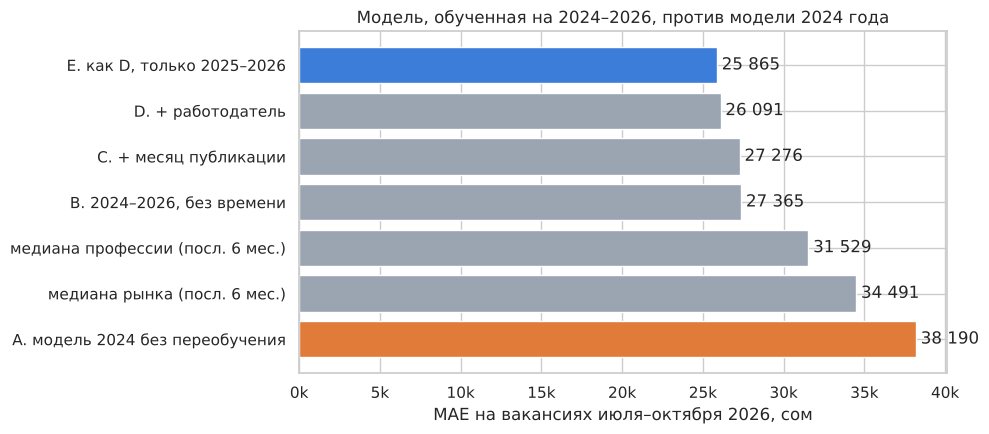

In [3]:
best = res.drop(index=[i for i in res.index if i.startswith("медиана")])["MAE, сом"].idxmin()
print("Лучшая модель:", best)
fig, ax = plt.subplots(figsize=(10, 4.5))
order = res.sort_values("MAE, сом").index
cols = ["#3b7dd8" if i == best else "#e07b39" if i.startswith("A.") else "#9aa5b1" for i in order]
ax.barh(order[::-1], res.loc[order[::-1], "MAE, сом"], color=cols[::-1])
for i, v in enumerate(res.loc[order[::-1], "MAE, сом"]):
    ax.text(v + 300, i, f"{v:,.0f}".replace(",", " "), va="center")
ax.xaxis.set_major_formatter(K); ax.set_xlabel("MAE на вакансиях июля–октября 2026, сом")
ax.set_title("Модель, обученная на 2024–2026, против модели 2024 года")
plt.tight_layout(); plt.savefig(FIG + "07_time_models.png", dpi=150); plt.show()

## Ошибка по источникам и уровням зарплаты (лучшая модель против модели 2024)

In [4]:
t = test.assign(best=np.exp(preds[best]), old=np.exp(preds["A. модель 2024 без переобучения"]))
t["band"] = pd.cut(t["salary_kgs"], [0, 25e3, 40e3, 60e3, 100e3, 1e9], labels=["<25k", "25–40k", "40–60k", "60–100k", "100k+"])
def seg(g):
    return pd.Series({"вакансий": len(g), "медиана зарплаты": g["salary_kgs"].median(),
                      "MAE модель 2024": (g["old"] - g["salary_kgs"]).abs().mean(),
                      "MAE новая модель": (g["best"] - g["salary_kgs"]).abs().mean(),
                      "медианная ошибка новой": (g["best"] - g["salary_kgs"]).abs().median(),
                      "смещение 2024, %": (g["old"] / g["salary_kgs"] - 1).median() * 100,
                      "смещение новой, %": (g["best"] / g["salary_kgs"] - 1).median() * 100})
tab = pd.concat([t.groupby("source").apply(seg), t.groupby("band", observed=True).apply(seg), seg(t).to_frame("весь тест").T])
tab.style.format({"вакансий": "{:.0f}", "медиана зарплаты": "{:,.0f}", "MAE модель 2024": "{:,.0f}", "MAE новая модель": "{:,.0f}",
                  "медианная ошибка новой": "{:,.0f}", "смещение 2024, %": "{:+.0f}", "смещение новой, %": "{:+.0f}"})

,вакансий,медиана зарплаты,MAE модель 2024,MAE новая модель,медианная ошибка новой,"смещение 2024, %","смещение новой, %"
telegram_codifynews,696,"75,000","48,735","30,155","18,129",-42,-1
telegram_kgworkzone,380,"50,000","18,877","18,006","12,456",-18,+6
<25k,26,"20,500","23,183","30,756","22,541",+99,+139
25–40k,169,"37,500","8,115","17,831","14,993",+7,+40
40–60k,305,"50,000","12,824","13,647","10,868",-20,+13
60–100k,374,"80,000","32,564","18,571","14,378",-42,-9
100k+,202,"150,000","114,002","63,909","50,115",-64,-33
весь тест,1076,"65,000","38,190","25,865","15,851",-33,+1


## Диапазон вместо одного числа

Ширина диапазона берётся из ошибок модели на **калибровочном** квартале (апрель–июнь 2026), для этого
модель переобучается на данных до апреля 2026. Затем проверяется, какая доля тестовых вакансий
(июль–октябрь) попала в диапазон. Это честная проверка: ни калибровка, ни тест не участвовали в обучении.

In [5]:
m_b, cat_b, num_b, since_b = fitted[best]
pre = train[train["published"] < CAL_FROM]
if since_b: pre = pre[pre["published"] >= since_b]
cal = train[train["published"] >= CAL_FROM]
cal = cal[~cal["dup_group"].isin(set(pre["dup_group"]))]
m_cal = build(cat_b, num_b).fit(pre, pre["y"])
resid = cal["y"].values - m_cal.predict(cal)
Q = {}
for src in sorted(d["source"].unique()):
    r = resid[(cal["source"] == src).values] if (cal["source"] == src).sum() >= 100 else resid
    Q[src] = {"50%": np.quantile(r, [.25, .75]).tolist(), "80%": np.quantile(r, [.1, .9]).tolist()}
rows_c = []
p = preds[best]
for lvl in ["50%", "80%"]:
    lo = np.array([Q[s][lvl][0] for s in test["source"]]); hi = np.array([Q[s][lvl][1] for s in test["source"]])
    inside = (test["y"].values >= p + lo) & (test["y"].values <= p + hi)
    for src in ["telegram_codifynews", "telegram_kgworkzone", "все"]:
        mask = np.ones(len(test), bool) if src == "все" else (test["source"] == src).values
        rows_c.append({"уровень": lvl, "источник": src, "покрытие на тесте": inside[mask].mean(),
                       "диапазон": f"×{np.exp(np.median(lo[mask])):.2f} … ×{np.exp(np.median(hi[mask])):.2f}"})
pd.DataFrame(rows_c).style.format({"покрытие на тесте": "{:.0%}"})

,уровень,источник,покрытие на тесте,диапазон
0,50%,telegram_codifynews,51%,×0.73 … ×1.25
1,50%,telegram_kgworkzone,48%,×0.81 … ×1.24
2,50%,все,50%,×0.73 … ×1.25
3,80%,telegram_codifynews,86%,×0.50 … ×1.75
4,80%,telegram_kgworkzone,75%,×0.66 … ×1.50
5,80%,все,82%,×0.50 … ×1.75


## Финальная модель для приложения

Лучший вариант переобучается на **всех** вакансиях 2024–2026 (включая тест). Для прогноза «на сегодня»
признак времени ставится равным текущему месяцу (октябрь 2026).

In [6]:
m_b, cat_b, num_b, since_b = fitted[best]
full = d if since_b is None else d[d["published"] >= since_b]
final = build(cat_b, num_b).fit(full, full["y"])
NOW = int(df["month_n"].max())
joblib.dump(final, "../models/model_2026.joblib", compress=3)
meta = {"variant": best, "params": P, "features": cat_b + num_b + ["full", "title"],
        "trained_on": int(len(full)), "period": [str(full["published"].min().date()), str(full["published"].max().date())],
        "month_n_now": NOW, "interval_log_quantiles": Q,
        "test": {k: float(v) for k, v in res.loc[best, ["MAE, сом", "медианная ошибка, сом", "MAPE, %", "R² (log)"]].items()}}
json.dump(meta, open("../models/model_2026_meta.json", "w"), ensure_ascii=False, indent=1)
print(f"Сохранено: models/model_2026.joblib, обучено на {len(full)} вакансиях, month_n сейчас = {NOW}")

Сохранено: models/model_2026.joblib, обучено на 12801 вакансиях, month_n сейчас = 33


### Пример: оценка зарплаты для нескольких вакансий сегодня

In [7]:
def ask(title, sub_category, category, experience=1, source="telegram_codifynews", city="Бишкек", company="не указано", text=""):
    row = {c: "не указано" for c in prep.CAT_FEATURES}
    row.update(dict(category=category, sub_category=sub_category, city=city, source=source, company=company.lower(),
                    experience_start=experience, n_skills=0, text_len=len(text), remote=0, commission=0, kyrgyz_text=0,
                    experience_known=1, month_n=NOW))
    row["title"] = prep.strip_money(pd.Series([title.lower()]))[0]
    row["full"] = row["title"] + ". " + prep.strip_money(pd.Series([text.lower()]))[0] + ". "
    x = pd.DataFrame([row]); p = final.predict(x)[0]; q = Q[source]
    return {"вакансия": title, "опыт": experience, "прогноз": np.exp(p),
            "50% диапазон": f"{np.exp(p + q['50%'][0]):,.0f} – {np.exp(p + q['50%'][1]):,.0f}",
            "80% диапазон": f"{np.exp(p + q['80%'][0]):,.0f} – {np.exp(p + q['80%'][1]):,.0f}"}

ex = pd.DataFrame([
    ask("Менеджер по продажам", "Менеджер по продажам, менеджер по работе с клиентами", "Продажи, обслуживание клиентов", 0),
    ask("Менеджер по продажам", "Менеджер по продажам, менеджер по работе с клиентами", "Продажи, обслуживание клиентов", 3),
    ask("SMM-менеджер", "SMM-менеджер, контент-менеджер", "Маркетинг, реклама, PR", 1),
    ask("Python разработчик", "Программист, разработчик", "Информационные технологии", 3),
    ask("Бухгалтер", "Бухгалтер", "Финансы, бухгалтерия", 1),
    ask("Официант", "Официант, бармен, бариста", "Туризм, гостиницы, рестораны", 0, source="telegram_kgworkzone"),
])
ex.style.format({"прогноз": "{:,.0f}"})

,вакансия,опыт,прогноз,50% диапазон,80% диапазон
0,Менеджер по продажам,0,"64,820","47,275 – 81,101","32,519 – 113,134"
1,Менеджер по продажам,3,"86,140","62,824 – 107,777","43,215 – 150,346"
2,SMM-менеджер,1,"40,419","29,479 – 50,571","20,278 – 70,546"
3,Python разработчик,3,"92,516","67,474 – 115,753","46,414 – 161,473"
4,Бухгалтер,1,"67,771","49,427 – 84,793","34,000 – 118,284"
5,Официант,0,"44,832","36,268 – 55,755","29,739 – 67,196"


## Выводы

1. **Модель 2024 года устарела.** На вакансиях июля–октября 2026 она занижает зарплату в среднем на **33%**
   (в codifynews на 42%), MAE 38 190 сом. Это хуже, чем простая медиана рынка за последние полгода (34 491).
2. **Переобучение на 2024–2026 убирает перекос:** смещение с −33% до **+1%**, MAE с 38 190 до **25 865 сом**
   (−32%), R² с −0,47 до 0,39.
3. **Что дало улучшение:**
   - новые данные (вариант B): 38 190 → 27 365;
   - признак времени (C): смещение с −6,5% до −0,9%, то есть модель «знает», что зарплаты растут;
   - работодатель (D): ещё −1 200 сом, один и тот же работодатель платит похоже;
   - обучение только на 2025–2026 (E): ещё немного лучше и в 2 раза меньше данных, старые цены мешают.
4. **Абсолютная ошибка выше, чем в ноутбуке 03 (15 763), но задача другая:** тест из «будущего», а
   типичная зарплата в тесте 65 000 сом против 35 000–40 000 в 2024. В процентах точность сопоставима:
   медианная ошибка 15 851 сом это около **24%** от типичной зарплаты (в 2024 было около 26%).
5. **Лучше всего модель работает в диапазоне 40–100 тыс. сом** (медианная ошибка 11–14 тыс.).
   Зарплаты выше 100 тыс. она занижает на треть, ниже 25 тыс. завышает: крайние значения редки и плохо
   предсказуемы по тексту объявления.
6. **Диапазоны честные:** 50% диапазон (×0,73 … ×1,25) накрыл ровно 50% тестовых вакансий,
   80% диапазон (×0,50 … ×1,75) накрыл 82%. Поэтому в приложении показывается диапазон, а не одно число.

**Для приложения** сохранена модель `models/model_2026.joblib` (вариант E, обучен на 12 801 вакансии
2025–2026) и `models/model_2026_meta.json` с диапазонами.